# Measles risk on the 2025 U.S. airport network: data pipeline

This notebook builds the **airport-level** flight network and attaches 2025 measles cases and MMR vaccination coverage to each airport. 

1. Build a directed network of airports, with each edge weighted by 2025 passengers (BTS T-100).
2. Give every airport and every county a latitude/longitude (OurAirports and Census county centroids).
3. Link each county to its **nearest airport in the network**, so each airport carries the measles cases and vaccination coverage of the counties around it (its *catchment*).

Keep this notebook in the `code/` folder and run the cells top to bottom. It reads from `data/` and writes to `output/`.

In [35]:
import numpy as np
import pandas as pd
import networkx as nx


# 50 states + DC. Anything else (Puerto Rico, Guam, ...) is left out of the network. Need to go re-check if I should exclude. 
STATES = ['AK', 'AL', 'AR', 'AZ', 'CA', 'CO', 'CT', 'DC', 'DE', 'FL', 'GA', 'HI', 'IA', 'ID',
          'IL', 'IN', 'KS', 'KY', 'LA', 'MA', 'MD', 'ME', 'MI', 'MN', 'MO', 'MS', 'MT', 'NC',
          'ND', 'NE', 'NH', 'NJ', 'NM', 'NV', 'NY', 'OH', 'OK', 'OR', 'PA', 'RI', 'SC', 'SD',
          'TN', 'TX', 'UT', 'VA', 'VT', 'WA', 'WI', 'WV', 'WY']

## Step 1. Build the airport network

**Airports.** The OurAirports file (all airports worldwide) gives each airport's IATA code (the 3-letter code BTS uses, e.g. `LBB`), its coordinates and its state (`iso_region`, e.g. `US-TX`).

In [36]:
ap = pd.read_csv('airports.csv', keep_default_na=False, na_values=[""])
ap = ap[(ap.iso_country == "US") & ap.iata_code.notna()]   # U.S. airports with a 3-letter code
ap["state"] = ap.iso_region.str.replace("US-", "", regex=False)
ap = ap[ap.state.isin(STATES)]

# A few IATA codes appear twice; keep the airport that has scheduled passenger service
ap = ap.sort_values("scheduled_service", ascending=False).drop_duplicates("iata_code")
ap = ap.set_index("iata_code")
ap.head()

,id,ident,type,name,latitude_deg,longitude_deg,elevation_ft,continent,iso_country,iso_region,municipality,scheduled_service,icao_code,gps_code,local_code,home_link,wikipedia_link,keywords,state
iata_code,,,,,,,,,,,,,,,,,,,
LSE,3654,KLSE,medium_airport,La Crosse Regional Airport,43.879002,-91.256699,655.0,NA,US,US-WI,La Crosse,yes,KLSE,KLSE,LSE,http://www.lseairport.com/,https://en.wikipedia.org/wiki/La_Crosse_Munici...,"airport, regional",WI
SLN,3891,KSLN,medium_airport,Salina Municipal Airport,38.791000,-97.652199,1288.0,NA,US,US-KS,Salina,yes,KSLN,KSLN,SLN,NaN,https://en.wikipedia.org/wiki/Salina_Municipal...,NaN,KS
FAT,3524,KFAT,large_airport,Fresno Yosemite International Airport,36.775767,-119.718018,336.0,NA,US,US-CA,Fresno,yes,KFAT,KFAT,FAT,https://flyfresno.com/,https://en.wikipedia.org/wiki/Fresno_Yosemite_...,NaN,CA
FAY,3525,KFAY,medium_airport,Fayetteville Regional Airport - Grannis Field,34.991199,-78.880302,189.0,NA,US,US-NC,Fayetteville,yes,KFAY,KFAY,FAY,NaN,https://en.wikipedia.org/wiki/Fayetteville_Reg...,NaN,NC
SPI,3897,KSPI,medium_airport,Abraham Lincoln Capital Airport,39.844101,-89.677902,598.0,NA,US,US-IL,Springfield,yes,KSPI,KSPI,SPI,NaN,https://en.wikipedia.org/wiki/Abraham_Lincoln_...,NaN,IL


**Flights.** `BTS2025.csv` has one row per carrier, route and month. We:
- drop rows with 0 passengers (cargo or empty repositioning flights) and rows where origin = destination,
- **sum passengers over all months and carriers**, so each directed airport pair (origin → destination) becomes one edge,
- keep only routes whose two airports have coordinates and are in the 50 states + DC,
- keep routes with **at least 1,000 passengers** in the year (the same cut-off as the course notebook), which removes rare charter routes.

In [ ]:
MIN_PASSENGERS = 1000

b = pd.read_csv('T_T100D_SEGMENT_US_CARRIER_ONLY.csv') #the BTS2025 file we currently have doesn't actually include all flights in 2025, this file does (but it's too big to put into the github)
b = b[(b.PASSENGERS > 0) & (b.ORIGIN != b.DEST)]

edges = (b.groupby(["ORIGIN", "DEST"], as_index=False).PASSENGERS.sum()
          .rename(columns={"ORIGIN": "origin", "DEST": "dest", "PASSENGERS": "passengers"}))

total = edges.passengers.sum()
edges = edges[edges.origin.isin(ap.index) & edges.dest.isin(ap.index)]
print(f"Dropped {1 - edges.passengers.sum() / total:.1%} of passengers "
      "(airports without coordinates or outside the 50 states + DC)")

edges = edges[edges.passengers >= MIN_PASSENGERS]
edges.to_csv("airport_edges_2025.csv", index=False)
edges.sort_values("passengers", ascending=False).head()

Dropped 2.7% of passengers (airports without coordinates or outside the 50 states + DC)


,origin,dest,passengers
12005,LAX,JFK,1463950.0
10949,JFK,LAX,1449013.0
16039,ORD,LGA,1387132.0
12425,LGA,ORD,1382488.0
12082,LAX,SFO,1366159.0


**Node table.** One row per airport in the network, with its coordinates and total passengers flying out and in.

In [38]:
codes = sorted(set(edges.origin) | set(edges.dest))
nodes = ap.loc[codes, ["name", "state", "latitude_deg", "longitude_deg"]].rename(
    columns={"latitude_deg": "lat", "longitude_deg": "lon"})
nodes["passengers_out"] = edges.groupby("origin").passengers.sum()
nodes["passengers_in"] = edges.groupby("dest").passengers.sum()
nodes = nodes.fillna({"passengers_out": 0, "passengers_in": 0})
nodes.index.name = "airport"
nodes.to_csv("nodes.csv")

print(f"Airport network: {len(nodes)} airports, {len(edges)} directed routes, "
      f"{edges.passengers.sum():,.0f} passengers")

Airport network: 576 airports, 8156 directed routes, 823,290,902 passengers


## Step 2. Put measles cases and MMR coverage on counties

Every county gets a latitude/longitude from the Census Gazetteer county centroid file (the FIPS lat/long file), keyed by its 5-digit FIPS code.

A few rows in the measles and MMR data use a **region instead of a county**. The dictionaries below place them in a county by hand:
- large measles reporting regions go to the county with most of the region's population,
- Connecticut now reports by *planning region* (FIPS 09110–09190), which the centroid file doesn't have, so each region goes to the old county it mostly overlaps,
- Alaska's MMR data is by region with no FIPS code.

Anything else without a county (e.g. "Unknown County, Kansas") is listed and left out.

In [39]:
REGION_TO_FIPS = {
    "Southwest Health District, Utah": "49053",             # Washington County, UT
    "Twin Cities Metro Area, Minnesota": "27053",           # Hennepin County, MN
    "Memphis-Shelby County Region, Tennessee": "47157",     # Shelby County, TN
    "Nashville-Davidson County Region, Tennessee": "47037", # Davidson County, TN
}
CT_REGION_TO_COUNTY = {
    "09110": "09003", "09120": "09001", "09130": "09007", "09140": "09009", "09150": "09015",
    "09160": "09005", "09170": "09009", "09180": "09011", "09190": "09001",
}
AK_REGION_TO_FIPS = {
    "Anchorage": "02020", "Gulf Coast": "02122", "Interior": "02090", "Mat-Su": "02170",
    "Northern": "02185", "Southeast": "02110", "Southwest": "02050",
}

def fips5(s):
    """Numeric FIPS (e.g. 1001.0) -> 5-character string with leading zero ('01001')."""
    return s.astype("Int64").astype("string").str.zfill(5)

# Tab-separated Census Gazetteer file; column names have trailing spaces, so strip them
cent = pd.read_csv('counties.txt', sep="\t", dtype={"GEOID": str})
cent.columns = cent.columns.str.strip()
cent = (cent.rename(columns={"USPS": "state", "GEOID": "fips", "NAME": "county",
                             "INTPTLAT": "lat", "INTPTLONG": "lon"})
            [["fips", "state", "county", "lat", "lon"]]
            .set_index("fips"))
cent = cent[cent.state.isin(STATES)]
cent.head()

,state,county,lat,lon
fips,,,,
01001,AL,Autauga County,32.532237,-86.646440
01003,AL,Baldwin County,30.659218,-87.746067
01005,AL,Barbour County,31.870253,-85.405104
01007,AL,Bibb County,33.015893,-87.127148
01009,AL,Blount County,33.977358,-86.566440


**Measles.** We keep `case_lab-confirmed` rows reported in **2025**. Each row is the number of *new* cases in that update, so cases are **summed** per county. The other outcome types (local, imported, vaccinated...) are breakdowns of the same cases, so they are not added. We also keep each county's **first 2025 report date**, which is used later to test effective distance.

In [40]:
m = pd.read_csv('measles_county_all_updates_detailed.csv.txt', parse_dates=["date"])
m = m[(m.outcome_type == "case_lab-confirmed") & (m.date.dt.year == 2025)].copy()

m["fips"] = fips5(m.location_id)
m.loc[m.location_id.fillna(0) < 1000, "fips"] = pd.NA      # region / "Unknown County" rows
m["fips"] = m.fips.fillna(m.location_name.map(REGION_TO_FIPS)).replace(CT_REGION_TO_COUNTY)

lost = m[m.fips.isna() | ~m.fips.isin(cent.index)]
print(f"{m.value.sum()} lab-confirmed cases in 2025; {lost.value.sum()} could not be placed in a county")
display(lost.groupby("location_name").value.sum().sort_values(ascending=False).to_frame("cases"))

m = m.drop(lost.index)
measles = m.groupby("fips").agg(cases_2025=("value", "sum"), first_case_date=("date", "min"))

2286 lab-confirmed cases in 2025; 79 could not be placed in a county


,cases
location_name,
"Unknown County, Kansas",20
"Unknown County, Minnesota",11
"Eastern, Iowa",6
"Bear River, Utah",4
"Upper Cumberland Region, Tennessee",4
"Northwest Region, Virginia",3
"Mid-Cumberland Region, Tennessee",3
"Central, Utah",3
"Unknown County, California",3


**MMR.** Kindergarten MMR coverage for the **2024–25 school year** (`SY2024_25`), one value per county.

In [41]:
v = pd.read_csv('mmr_data_us_counties_v2 (.csv', encoding="utf-8-sig")
v["fips"] = fips5(v.FIPS)
ak = v.State.eq("AK") & v.fips.isna()
v.loc[ak, "fips"] = v.loc[ak, "County"].map(AK_REGION_TO_FIPS)
v["fips"] = v.fips.replace(CT_REGION_TO_COUNTY)
v = v[v.SY2024_25.notna()]

mmr = v.groupby("fips").SY2024_25.mean().rename("mmr_2024_25")   # merged CT regions are averaged
print(f"{len(mmr)} counties with 2024-25 coverage; states with none: "
      f"{sorted(set(cent.state) - set(v.State))}")

2717 counties with 2024-25 coverage; states with none: ['AR', 'DE', 'GA', 'MT', 'WV', 'WY']


**One row per county**: coordinates + cases + first case date + MMR. Counties with no reported cases get 0.

In [42]:
county = cent.join(measles).join(mmr)
county["cases_2025"] = county.cases_2025.fillna(0).astype(int)
county.index.name = "fips"
county.to_csv("../output/county_measles_mmr_2025.csv")
print(f"{len(county)} counties, {county.cases_2025.sum()} cases placed")
county.sort_values("cases_2025", ascending=False).head()

3142 counties, 2207 cases placed


,state,county,lat,lon,cases_2025,first_case_date,mmr_2024_25
fips,,,,,,,
48165,TX,Gaines County,32.743942,-102.631561,414,2025-02-05,0.772563
45083,SC,Spartanburg County,34.933271,-81.991052,330,2025-09-08,0.900000
04015,AZ,Mohave County,35.717705,-113.749689,216,2025-08-12,0.784000
49053,UT,Washington County,37.262531,-113.487800,155,2025-06-24,0.791591
35025,NM,Lea County,32.795687,-103.413271,67,2025-02-11,0.966600


## Step 3. Link each county to its nearest airport

We compute the **great-circle (haversine) distance** from every county centroid to every airport in the network and assign the county to the closest one. Then each airport's catchment is summarised:
- `cases_2025`: total cases in its counties
- `first_case_date`: earliest 2025 case in its counties
- `mmr_mean`: average MMR coverage of its counties (not population-weighted)
- `pct_counties_below_95`: share of its counties below the 95% herd-immunity level

In [43]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

# Distance matrix: rows = counties, columns = airports
D = haversine_km(county.lat.values[:, None], county.lon.values[:, None],
                 nodes.lat.values[None, :], nodes.lon.values[None, :])
nearest = D.argmin(axis=1)
county["airport"] = nodes.index.values[nearest]
county["dist_to_airport_km"] = D[np.arange(len(county)), nearest]
county.to_csv("county_nearest_airport.csv")

print(f"Median county-to-airport distance: {county.dist_to_airport_km.median():.0f} km; "
      f"for counties with cases: {county[county.cases_2025 > 0].dist_to_airport_km.median():.0f} km")

Median county-to-airport distance: 57 km; for counties with cases: 35 km


In [44]:
catch = county.groupby("airport").agg(
    n_counties=("county", "size"),
    cases_2025=("cases_2025", "sum"),
    first_case_date=("first_case_date", "min"),
    mmr_mean=("mmr_2024_25", "mean"),
    n_counties_with_mmr=("mmr_2024_25", "count"),
)
attrs = nodes.join(catch)
attrs["n_counties"] = attrs.n_counties.fillna(0).astype(int)
attrs["cases_2025"] = attrs.cases_2025.fillna(0).astype(int)
attrs.to_csv("airport_attributes_2025.csv")

print(f"{(attrs.n_counties > 0).sum()} of {len(attrs)} airports are nearest to at least one county; "
      f"{(attrs.cases_2025 > 0).sum()} have cases in their catchment")
attrs.sort_values("cases_2025", ascending=False).head(10)[
    ["name", "state", "cases_2025", "first_case_date", "mmr_mean"]]

448 of 576 airports are nearest to at least one county; 142 have cases in their catchment


,name,state,cases_2025,first_case_date,mmr_mean
airport,,,,,
HOB,Lea County Regional Airport,NM,501,2025-02-05,0.895106
GSP,Greenville-Spartanburg International Airport,SC,330,2025-09-08,0.944200
IFP,Laughlin Bullhead International Airport,AZ,216,2025-08-12,0.784000
SGU,St George Regional Airport,UT,155,2025-06-24,0.743796
LBB,Lubbock Preston Smith International Airport,TX,144,2025-02-14,0.939616
ELP,El Paso International Airport,TX,61,2025-04-09,0.960218
MAF,Midland International Air and Space Port,TX,52,2025-02-21,0.940118
GCK,Garden City Regional Airport,KS,48,2025-04-09,0.917425
GRB,Austin Straubel International Airport,WI,36,2025-07-13,0.853333


## Step 4. Load everything into networkx

The edges file becomes the graph, and the airport attribute table is attached to the nodes. This graph is the starting point for the analysis (degree, betweenness, effective distance).

In [45]:
G = nx.from_pandas_edgelist(edges, "origin", "dest", edge_attr="passengers",
                            create_using=nx.DiGraph)
nx.set_node_attributes(G, attrs.to_dict("index"))
print(G)
G.nodes["LBB"]



DiGraph with 576 nodes and 8156 edges


{'name': 'Lubbock Preston Smith International Airport',
 'state': 'TX',
 'lat': 33.663601,
 'lon': -101.822998,
 'passengers_out': 569834.0,
 'passengers_in': 565617.0,
 'n_counties': 15,
 'cases_2025': 144,
 'first_case_date': Timestamp('2025-02-14 00:00:00'),
 'mmr_mean': 0.9396157333333334,
 'n_counties_with_mmr': 15.0}

In [46]:
import json, urllib.request
import matplotlib.pyplot as plt

with open('us-states.json') as f:
    us_states = json.load(f)

def draw_us_map(ax):
    for state in us_states["features"]:
        if state["properties"]["name"] in ["Alaska", "Hawaii", "Puerto Rico"]:
            continue
        geom = state["geometry"]
        shapes = [geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"]
        for shape in shapes:
            border = np.array(shape[0])
            ax.fill(border[:, 0], border[:, 1], color="#eeeeee", edgecolor="gray", linewidth=0.5)
    ax.set_xlim(-125, -66)
    ax.set_ylim(24, 50)
    ax.axis("off")

In [47]:
a = attrs[~attrs.state.isin(["AK", "HI"])]                 # lower 48 only
top = edges[edges.origin.isin(a.index) & edges.dest.isin(a.index)].nlargest(300, "passengers")
size = 2 + (a.passengers_out + a.passengers_in) / 1e5     # bigger dot = busier airport

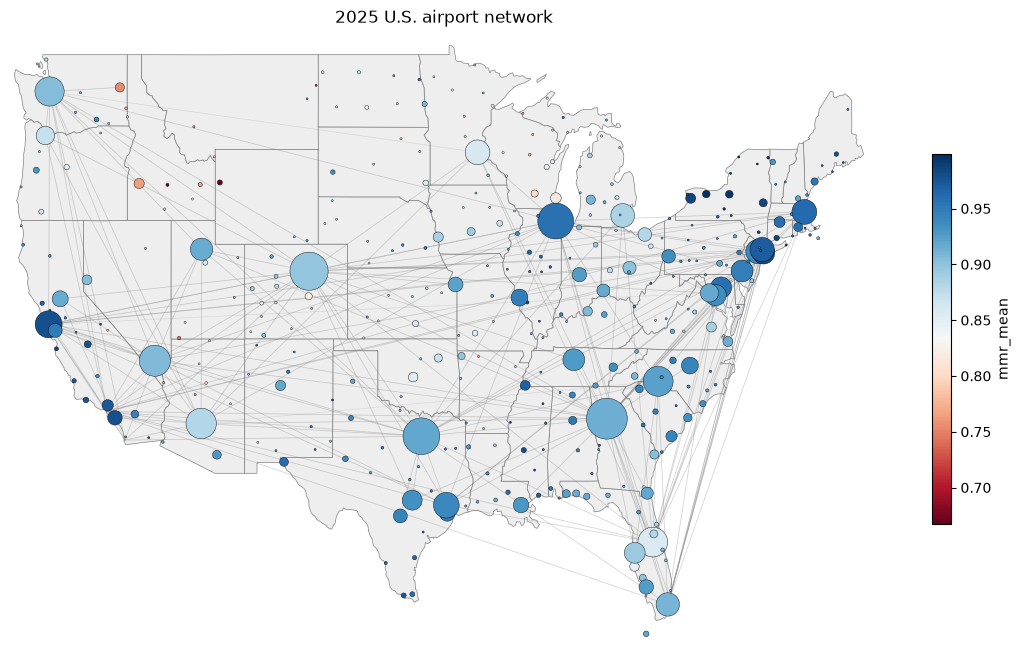

In [48]:
color = "mmr_mean"

fig, ax = plt.subplots(figsize=(14, 8))
draw_us_map(ax)
for _, r in top.iterrows():                                # one gray line per route
    ax.plot([a.lon[r.origin], a.lon[r.dest]], [a.lat[r.origin], a.lat[r.dest]],
            color="gray", alpha=0.2, linewidth=0.5)
dots = ax.scatter(a.lon, a.lat, s=size, c=a[color], cmap="RdBu_r" if color != "mmr_mean" else "RdBu",
                  edgecolors="black", linewidths=0.3, zorder=3)
plt.colorbar(dots, ax=ax, shrink=0.6, label=color)
ax.set_title("2025 U.S. airport network")
#for code in a.index:
#    ax.text(a.lon[code], a.lat[code], code, fontsize=5) code for including airport codes for each airport, but it looks very clustered. 
plt.savefig(f"map_{color}.png", dpi=200)

plt.show()